# Training data inspection 

Crop and irrigation types ground- truth dataset for Moroccan agricultural regions

https://www.nature.com/articles/s41597-026-06993-y



1. Load the survey
2. Data quality: geometry, duplicates, label spelling
3. Irrigated / rainfed labels
4. Map of the labelled parcels
5. Class balance
6. Parcel size and pixels per parcel
7. Survey timing (which agricultural season a label belongs to)
8. Spatial clustering and what a random train / test split leaks
9. Agreement with the ESA WorldCover cropland mask
10. Save the labelled parcels for the split and model notebooks



In [83]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from matplotlib.patches import Patch
from rasterio.mask import mask as rio_mask
from scipy.spatial import cKDTree
from shapely.ops import unary_union

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

In [84]:
ROOT = Path.cwd()
DATA = ROOT / "Morocco_data"
FIELDS_FILE = DATA / "Shapefile_Crop and irrigation dataset" / "lulc_fielddata.shp"
COUNTRY_FILE = DATA / "Morocco_Admin_Boundary" / "gadm41_MAR_0.json"
WORLDCOVER_FILE = DATA / "ESA_LULC_2021" / "ESA_WorldCover_10m_2021.tif"
OUT_DIR = ROOT / "outputs" / "inspect"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Metric CRS for areas and distances. UTM 29N covers the surveyed farm belt (about 10°W to 6°W).
UTM = 32629


CLASS_NAMES = {1: "Irrigated", 2: "Rainfed"}
CLASS_COLORS = {"Irrigated": "#1f77b4", "Rainfed": "#d62728"}
CLASSES = ["Irrigated", "Rainfed"]

def save(fig, name):
    path = OUT_DIR / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Saved {path.relative_to(ROOT)}")

## 1. Load the survey

Only three attributes matter for this study: `irrigation` (gives the class), `crop` (used once, to drop non-cropland such as bare soil, weed and water) and `date` (which season the label describes).

In [85]:
raw = gpd.read_file(FIELDS_FILE)
country = gpd.read_file(COUNTRY_FILE).to_crs(4326)

print(f"{len(raw):,} parcels, CRS {raw.crs}")
print(f"Survey dates: {raw['date'].min():%Y-%m-%d} to {raw['date'].max():%Y-%m-%d}")
raw[["parcel_id", "date", "crop", "irrigation", "geometry"]].head()

10,383 parcels, CRS EPSG:4326
Survey dates: 2023-12-07 to 2025-01-30


,parcel_id,date,crop,irrigation,geometry
0,Souss_mixte_20241216_001,2024-12-16,Trees + Seasonal,Drip Irrigation,"POLYGON ((-9.38249 30.33272, -9.38334 30.33273..."
1,Souss_mixte_20241216_002,2024-12-16,Trees + Seasonal,Drip Irrigation,"POLYGON ((-9.38192 30.33269, -9.38196 30.33558..."
2,Souss_Trees_20241216_001,2024-12-16,Trees,rainfed,"POLYGON ((-9.37804 30.33244, -9.38024 30.33252..."
3,Souss_Trees_20241216_002,2024-12-16,Trees,rainfed,"POLYGON ((-9.37028 30.33174, -9.36963 30.33881..."
4,Souss_Trees_20241216_003,2024-12-16,Trees,rainfed,"POLYGON ((-9.36624 30.3316, -9.36605 30.33855,..."


## 2. Data quality

In [86]:
has_geom = raw.geometry.notna()
geom = raw.geometry[has_geom]
pd.Series({
    "parcels": len(raw),
    "missing geometry": int((~has_geom).sum()),
    "empty geometry": int(geom.is_empty.sum()),
    "invalid geometry": int((~geom.is_valid).sum()),
    "duplicate parcel_id": int(raw["parcel_id"].duplicated().sum()),
    "duplicate geometry": int(geom.to_wkb().duplicated().sum()),
    "missing date": int(raw["date"].isna().sum()),
    "missing irrigation": int(raw["irrigation"].isna().sum()),
}, name="count").to_frame()

,count
parcels,10383
missing geometry,1
empty geometry,0
invalid geometry,2
duplicate parcel_id,0
duplicate geometry,0
missing date,0
missing irrigation,1557


In [87]:
# Raw spellings of the irrigation field.
raw["irrigation"].value_counts(dropna=False).to_frame()

,count
irrigation,
Flood Irrigation,3021
Drip Irrigation,2890
None,1557
Sprinkler Irrigation,1245
Rainfed,700
rainfed,516
Basin Irrigation,420
Pivot Irrigation,33
Flood IrrigationFlood Irrigation,1


Fixes:

- Drop the parcel without geometry and repair invalid polygons.
- Irrigation values are lower-cased and trimmed, so `Rainfed` / `rainfed` and the duplicated `Flood IrrigationFlood Irrigation` are read correctly.

In [88]:
def repair(g):
    # make_valid / buffer(0) can return a GeometryCollection; keep only polygon parts.
    if g.is_valid:
        return g
    g = g.buffer(0) if g.geom_type in ("Polygon", "MultiPolygon") else g
    if g.geom_type in ("Polygon", "MultiPolygon"):
        return g
    return unary_union([p for p in getattr(g, "geoms", []) if p.geom_type in ("Polygon", "MultiPolygon")])

df = raw[has_geom].copy()
df["geometry"] = df.geometry.apply(repair)
df["irr_text"] = df["irrigation"].astype(str).str.strip().str.lower()
print(f"{len(df):,} parcels with geometry, invalid after repair: {(~df.is_valid).sum()}")

10,382 parcels with geometry, invalid after repair: 0


## 3. Irrigated / rainfed labels

- **Irrigated** = any irrigation method recorded (drip, flood, sprinkler, basin, pivot). Pivot was missing from `2_split_train_test.ipynb`.
- **Rainfed** = rainfed.
- Only cropland parcels are kept (Seasonal Crop, Trees, Trees + Seasonal); bare soil, weed, water and parcels without irrigation information are left out.

In [89]:
CROP_KEEP = ["Seasonal Crop", "Trees", "Trees + Seasonal"]
IRRIGATED_TEXT = ["drip irrigation", "flood irrigation", "flood irrigationflood irrigation",
                  "sprinkler irrigation", "basin irrigation", "pivot irrigation"]

df["label"] = np.select([df["irr_text"].isin(IRRIGATED_TEXT), df["irr_text"].eq("rainfed")], [1, 2], default=0)
is_cropland = df["crop"].isin(CROP_KEEP)

pd.Series({
    "surveyed": len(raw),
    "with geometry": len(df),
    "cropland": int(is_cropland.sum()),
    "cropland with irrigated / rainfed label": int((is_cropland & (df["label"] > 0)).sum()),
}, name="parcels").to_frame()

,parcels
surveyed,10383
with geometry,10382
cropland,8786
cropland with irrigated / rainfed label,8781


In [90]:
lab = df[is_cropland & (df["label"] > 0)].copy()
lab["class_name"] = lab["label"].map(CLASS_NAMES)
lab_proj = lab.to_crs(UTM)
lab["area_ha"] = lab_proj.area / 10_000
cent = lab_proj.centroid
lab["x_utm"], lab["y_utm"] = cent.x, cent.y
cent_ll = cent.to_crs(4326)
lab["lon"], lab["lat"] = cent_ll.x, cent_ll.y
lab["survey_month"] = lab["date"].dt.to_period("M")
print(f"Labelled parcels: {len(lab):,}")

Labelled parcels: 8,781


## 4. Map

Saved outputs/inspect/morocco_parcels_map.png


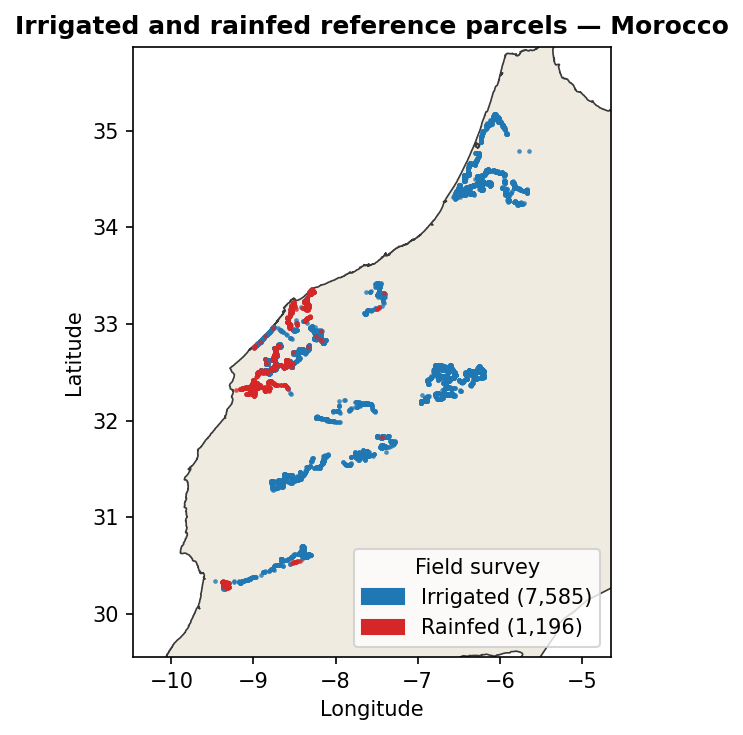

In [91]:
fig, ax = plt.subplots(figsize=(5,5), dpi=150)
country.plot(ax=ax, facecolor="#f0ebe0", edgecolor="#3a3a3a", linewidth=0.8, zorder=1)
counts = lab["class_name"].value_counts()
for name in CLASSES:
    sub = lab[lab["class_name"] == name]
    ax.scatter(sub["lon"], sub["lat"], s=5, c=CLASS_COLORS[name], alpha=0.8, linewidths=0, zorder=3)
xmin, ymin, xmax, ymax = lab[["lon", "lat"]].agg(["min", "max"]).T.values.ravel()[[0, 2, 1, 3]]
ax.set_xlim(xmin - 1.0, xmax + 1.0)
ax.set_ylim(ymin - 0.7, ymax + 0.7)
ax.legend(handles=[Patch(color=CLASS_COLORS[n], label=f"{n} ({counts[n]:,})") for n in CLASSES],
          title="Field survey", loc="lower right")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Irrigated and rainfed reference parcels — Morocco", fontweight="bold")
fig.tight_layout()
save(fig, "morocco_parcels_map.png")
plt.show()

## 5. Class balance

In [10]:
balance = lab["class_name"].value_counts().reindex(CLASSES).to_frame("parcels")
balance["share %"] = (100 * balance["parcels"] / balance["parcels"].sum()).round(1)
balance["area ha"] = lab.groupby("class_name")["area_ha"].sum().reindex(CLASSES).round(0).astype(int)
balance["area share %"] = (100 * balance["area ha"] / balance["area ha"].sum()).round(1)
balance

,parcels,share %,area ha,area share %
class_name,,,,
Irrigated,7585,86.4,13054,86.0
Rainfed,1196,13.6,2122,14.0


Saved outputs/inspect/class_balance.png


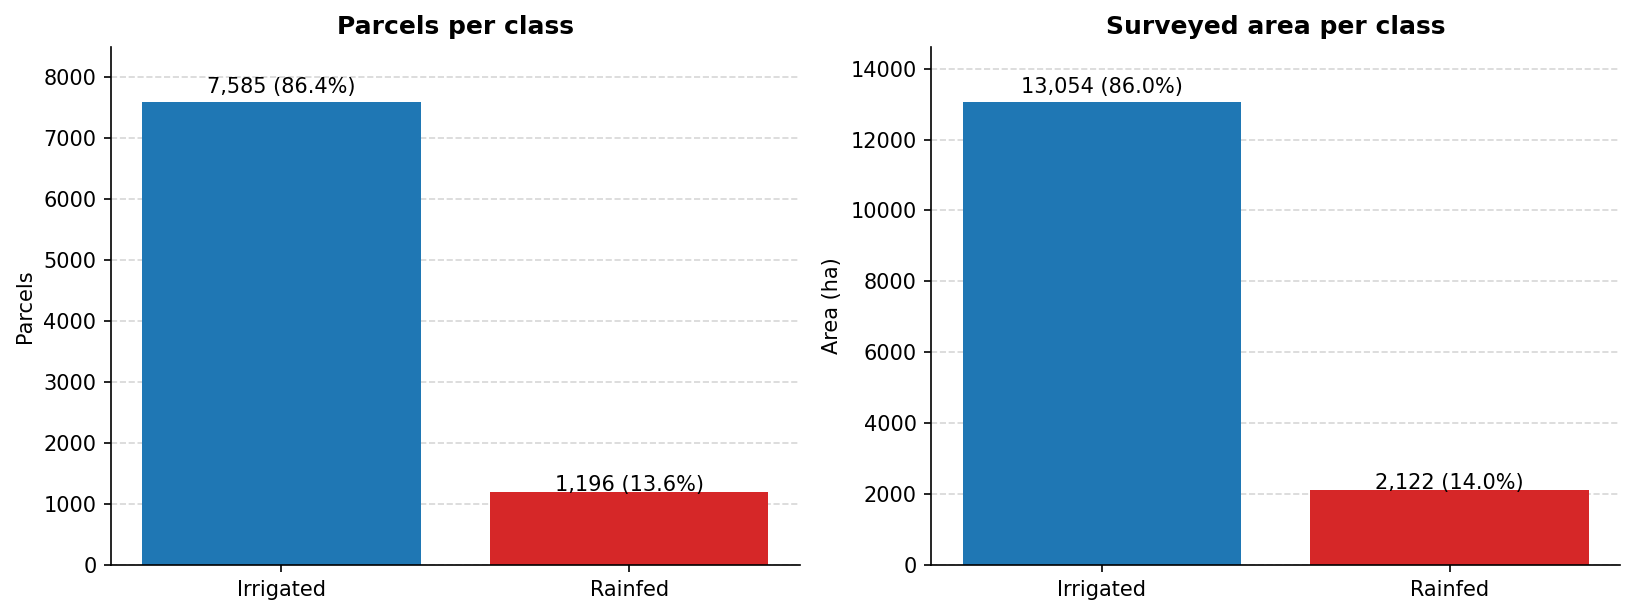

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), dpi=150)
for ax, col, share, ylabel in [(axes[0], "parcels", "share %", "Parcels"), (axes[1], "area ha", "area share %", "Area (ha)")]:
    ax.bar(CLASSES, balance[col], color=[CLASS_COLORS[n] for n in CLASSES])
    for i, n in enumerate(CLASSES):
        ax.text(i, balance.loc[n, col] * 1.02, f"{balance.loc[n, col]:,} ({balance.loc[n, share]}%)", ha="center")
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, balance[col].max() * 1.12)
    ax.yaxis.grid(True, linestyle="--", alpha=0.5)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_title("Parcels per class", fontweight="bold")
axes[1].set_title("Surveyed area per class", fontweight="bold")
fig.tight_layout()
save(fig, "class_balance.png")
plt.show()

## 6. Parcel size

A parcel smaller than a few pixels is mostly mixed edge pixels at 10 m, and barely one pixel at 30 m (Prithvi's HLS resolution). Very large polygons may be digitising errors.

In [12]:
lab["px_10m"] = lab["area_ha"] * 100        # 10 m pixel = 0.01 ha
lab["px_30m"] = lab["area_ha"] * 10_000 / 900
lab.groupby("class_name")["area_ha"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(2)

,count,mean,std,min,5%,25%,50%,75%,95%,max
class_name,,,,,,,,,,
Irrigated,7585.0,1.72,3.15,0.03,0.24,0.48,0.86,1.73,5.62,76.85
Rainfed,1196.0,1.77,8.03,0.06,0.22,0.38,0.61,1.25,6.03,206.80


Saved outputs/inspect/parcel_size.png


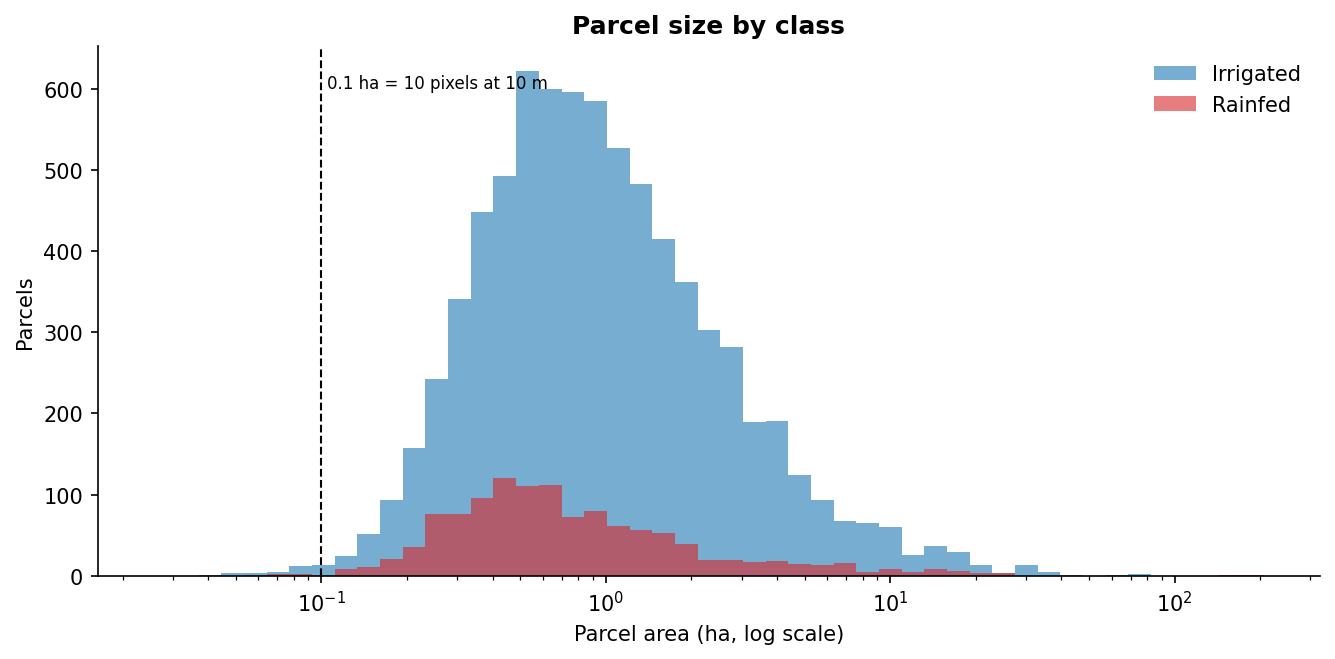

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5), dpi=150)
bins = np.logspace(np.log10(lab["area_ha"].min()), np.log10(lab["area_ha"].max()), 50)
for name in CLASSES:
    ax.hist(lab.loc[lab["class_name"] == name, "area_ha"], bins=bins, alpha=0.6, color=CLASS_COLORS[name], label=name)
ax.set_xscale("log")
ax.axvline(0.1, color="k", linestyle="--", linewidth=1)
ax.text(0.105, ax.get_ylim()[1] * 0.92, "0.1 ha = 10 pixels at 10 m", fontsize=8)
ax.set_xlabel("Parcel area (ha, log scale)")
ax.set_ylabel("Parcels")
ax.set_title("Parcel size by class", fontweight="bold")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save(fig, "parcel_size.png")
plt.show()

## 7. Survey timing

The 2024 annual imagery covers January–December 2024. The main Moroccan cropping season runs roughly October/November to May/June, so:

- surveys from **Dec 2023 – Aug 2024** describe the **2023/24 season**, which the 2024 imagery covers well;
- surveys from **Nov 2024 – Jan 2025** describe the **2024/25 season**, sown after most of the 2024 imagery. A field recorded as rainfed in December 2024 may have been irrigated earlier in 2024, or the reverse.

In [92]:
def season_of(d):
    # Agricultural season starting in September.
    y = d.year if d.month >= 9 else d.year - 1
    return f"{y}/{str(y + 1)[-2:]}"

lab["ag_season"] = lab["date"].apply(season_of)
pd.crosstab(lab["ag_season"], lab["class_name"], margins=True, margins_name="Total").reindex(columns=CLASSES + ["Total"], fill_value=0)

class_name,Irrigated,Rainfed,Total
ag_season,,,
2023/24,6189,698,6887
2024/25,1396,498,1894
Total,7585,1196,8781


Saved outputs/inspect/survey_timing.png


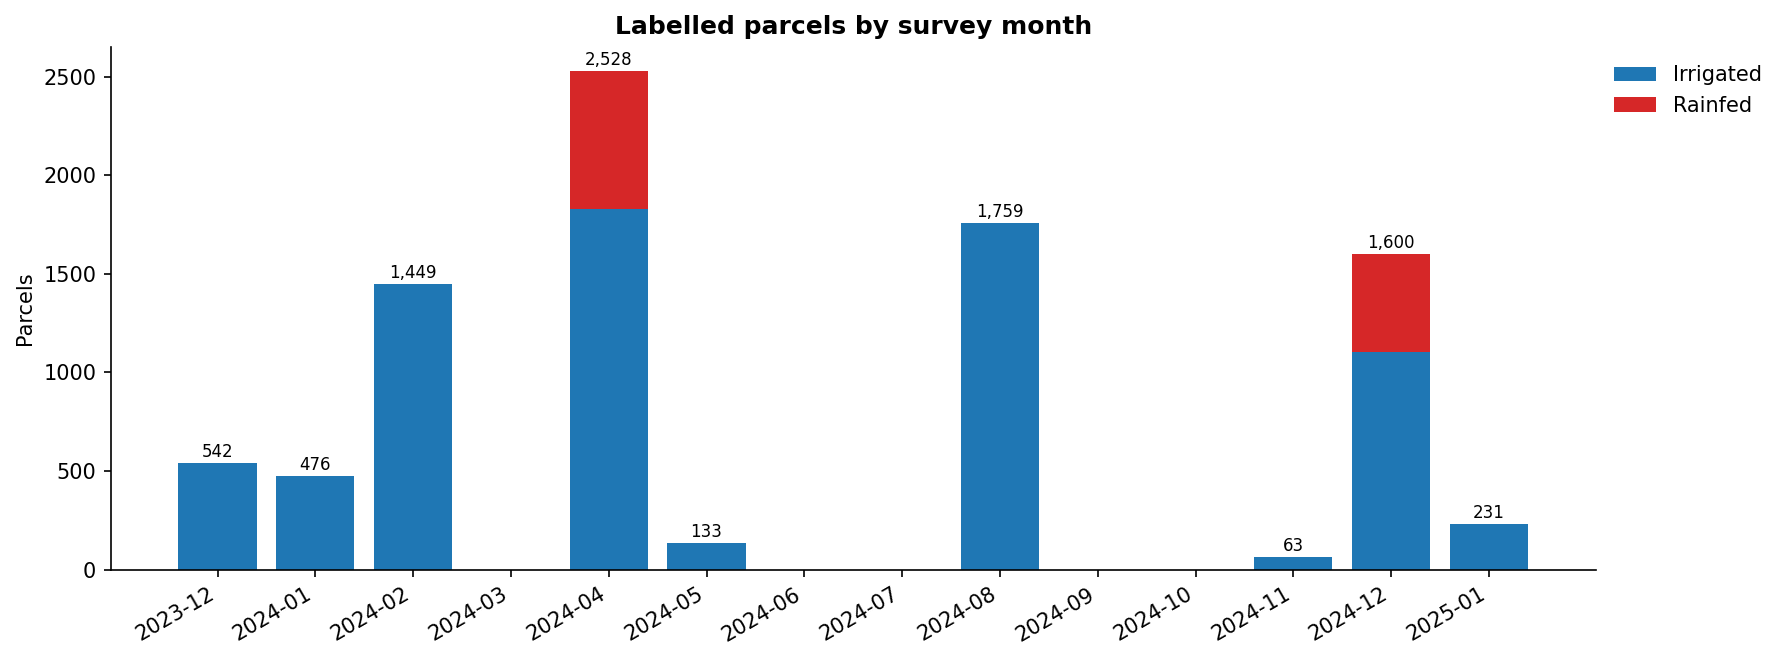

In [94]:
# Every month from first to last survey, so gaps between campaigns stay visible.
months = pd.period_range(lab["survey_month"].min(), lab["survey_month"].max(), freq="M")
timing = pd.crosstab(lab["survey_month"], lab["class_name"]).reindex(index=months, columns=CLASSES, fill_value=0)

fig, ax = plt.subplots(figsize=(12, 4.5), dpi=150)
x = np.arange(len(timing))
ax.bar(x, timing["Irrigated"], color=CLASS_COLORS["Irrigated"], label="Irrigated")
ax.bar(x, timing["Rainfed"], bottom=timing["Irrigated"], color=CLASS_COLORS["Rainfed"], label="Rainfed")
for i, (a, b) in enumerate(zip(timing["Irrigated"], timing["Rainfed"])):
    if a + b:
        ax.text(i, a + b + 30, f"{a + b:,}", ha="center", fontsize=8)

ax.set_xticks(x, [str(m) for m in months], rotation=30, ha="right")
ax.set_ylabel("Parcels")
ax.set_title("Labelled parcels by survey month", fontweight="bold")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save(fig, "survey_timing.png")
plt.show()

## 8. Spatial clustering

Surveyed parcels are dense and neighbours usually share the same class. With a random split, many test parcels have a training parcel a few hundred metres away, so test accuracy overstates how well a model works in places it has not seen.

In [95]:
xy = lab[["x_utm", "y_utm"]].to_numpy()
tree = cKDTree(xy)
d, i = tree.query(xy, k=2)
lab["nn_dist_m"] = d[:, 1]
nn_same = lab["label"].to_numpy()[i[:, 1]] == lab["label"].to_numpy()

print("Distance from each parcel to its nearest other parcel (m):")
print(lab["nn_dist_m"].describe(percentiles=[0.1, 0.5, 0.9]).round(0).to_string())
print(f"\nNearest neighbour has the same class: {nn_same.mean():.1%}")
print(pd.Series(nn_same, index=lab["class_name"]).groupby(level=0).mean().map("{:.1%}".format).to_string())

Distance from each parcel to its nearest other parcel (m):
count     8781.0
mean       182.0
std        297.0
min          2.0
10%         60.0
50%        122.0
90%        330.0
max      10487.0

Nearest neighbour has the same class: 95.9%
class_name
Irrigated    97.8%
Rainfed      84.1%


In [96]:
# How many rainfed parcels fall in square blocks of different sizes: guides the block size for a spatial split.
rows = []
for km in [2, 5, 10, 20]:
    block = (np.floor(lab["x_utm"] / (km * 1000)).astype(int).astype(str) + "_" +
             np.floor(lab["y_utm"] / (km * 1000)).astype(int).astype(str))
    per_block = pd.crosstab(block, lab["class_name"]).reindex(columns=CLASSES, fill_value=0)
    rows.append({
        "block size (km)": km,
        "blocks with parcels": len(per_block),
        "blocks with rainfed": int((per_block["Rainfed"] > 0).sum()),
        "blocks with both classes": int(((per_block["Rainfed"] > 0) & (per_block["Irrigated"] > 0)).sum()),
        "median parcels per block": int(per_block.sum(axis=1).median()),
    })
pd.DataFrame(rows).set_index("block size (km)")

,blocks with parcels,blocks with rainfed,blocks with both classes,median parcels per block
block size (km),,,,
2,1138,226,117,5
5,461,104,69,10
10,204,55,44,26
20,91,25,23,61


## 9. Agreement with the ESA WorldCover cropland mask

Maps are drawn only inside a cropland mask. For each parcel this measures the share of its 10 m pixels that WorldCover 2021 calls cropland (class 40). Parcels that WorldCover maps as tree cover or grassland would be lost under a WorldCover-only mask.

In [97]:
WC_NAMES = {10: "Tree cover", 20: "Shrubland", 30: "Grassland", 40: "Cropland", 50: "Built-up",
            60: "Bare / sparse", 70: "Snow / ice", 80: "Water", 90: "Herbaceous wetland", 95: "Mangroves", 100: "Moss / lichen"}

crop_frac, major = [], []
with rasterio.open(WORLDCOVER_FILE) as src:
    for g in lab.geometry:
        try:
            arr, _ = rio_mask(src, [g], crop=True, filled=False)
            v = arr.compressed()
            v = v[v > 0]
        except ValueError:
            v = np.array([], dtype=np.uint8)
        if v.size == 0:
            crop_frac.append(np.nan)
            major.append(None)
            continue
        crop_frac.append((v == 40).mean())
        vals, cnt = np.unique(v, return_counts=True)
        major.append(WC_NAMES.get(int(vals[cnt.argmax()]), str(vals[cnt.argmax()])))

lab["wc_cropland_frac"] = crop_frac
lab["wc_major"] = major
print(f"Parcels with no WorldCover pixel inside: {lab['wc_cropland_frac'].isna().sum()}")
lab.groupby("class_name").agg(
    parcels=("label", "size"),
    mean_cropland_share=("wc_cropland_frac", "mean"),
    mostly_cropland=("wc_cropland_frac", lambda s: (s >= 0.5).mean()),
).round(2)

Parcels with no WorldCover pixel inside: 0


,parcels,mean_cropland_share,mostly_cropland
class_name,,,
Irrigated,7585,0.79,0.80
Rainfed,1196,0.94,0.95


In [98]:
# Most common WorldCover class inside each parcel (% of parcels).
pd.crosstab(lab["class_name"], lab["wc_major"], normalize="index").mul(100).round(1)

wc_major,Bare / sparse,Cropland,Grassland,Herbaceous wetland,Shrubland,Tree cover
class_name,,,,,,
Irrigated,0.8,79.9,9.6,0.0,2.5,7.3
Rainfed,0.0,94.8,3.1,0.0,2.1,0.0


Saved outputs/inspect/worldcover_agreement.png


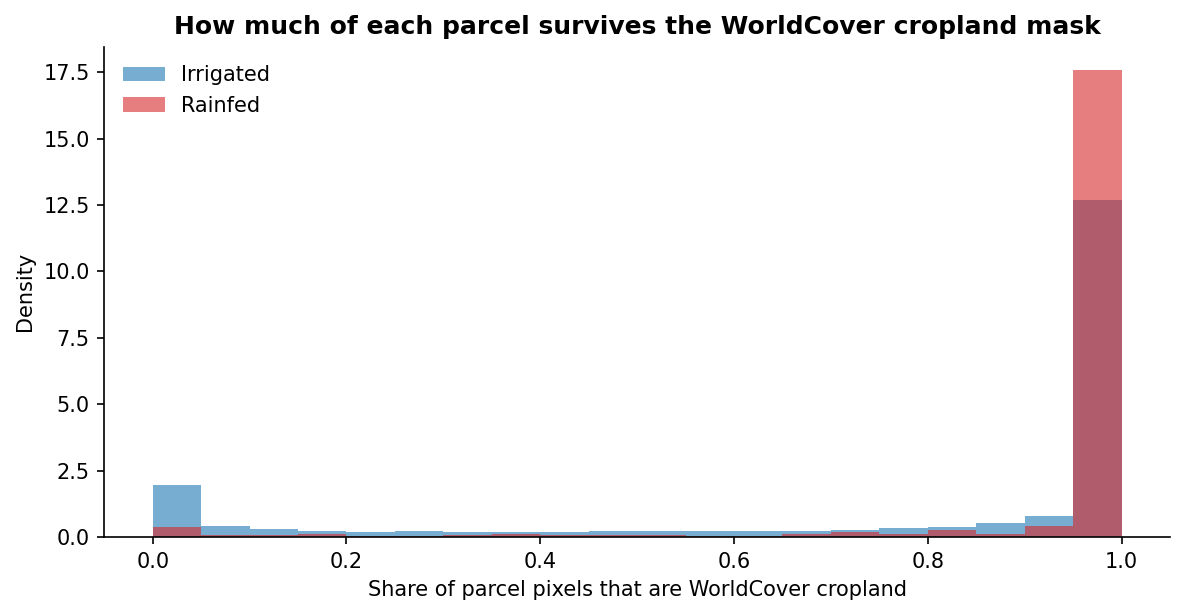

In [99]:
fig, ax = plt.subplots(figsize=(8, 4.2), dpi=150)
bins = np.linspace(0, 1, 21)
for name in CLASSES:
    ax.hist(lab.loc[lab["class_name"] == name, "wc_cropland_frac"].dropna(), bins=bins, alpha=0.6,
            color=CLASS_COLORS[name], label=name, density=True)
ax.set_xlabel("Share of parcel pixels that are WorldCover cropland")
ax.set_ylabel("Density")
ax.set_title("How much of each parcel survives the WorldCover cropland mask", fontweight="bold")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save(fig, "worldcover_agreement.png")
plt.show()

## 10. Save the labelled parcels

One file for the split and model notebooks.

In [100]:
keep_cols = ["parcel_id", "date", "ag_season", "label", "class_name", "area_ha", "nn_dist_m",
             "wc_cropland_frac", "wc_major", "zone", "geometry"]
out = lab[keep_cols].copy()
out["date"] = out["date"].dt.strftime("%Y-%m-%d")
out_file = OUT_DIR / "morocco_parcels_labelled.geojson"
out_file.write_text(out.to_json(drop_id=True))
balance.to_csv(OUT_DIR / "class_balance.csv")
print(f"Saved {out_file.relative_to(ROOT)} ({len(out):,} parcels)")
print(f"Saved {(OUT_DIR / 'class_balance.csv').relative_to(ROOT)}")

Saved outputs/inspect/morocco_parcels_labelled.geojson (8,781 parcels)
Saved outputs/inspect/class_balance.csv


## Key findings

**Labels**
- 8,781 labelled cropland parcels: 7,585 irrigated and 1,196 rainfed. Rainfed is the minority class (13.6%), so report rainfed F1 / macro-F1, not only overall accuracy.


**Survey timing**
- 1,894 labels (22%) come from the Nov 2024 – Jan 2025 campaigns (2024/25 season), recorded after most of the 2024 imagery, including 498 rainfed parcels. Check whether these parcels behave differently, or use an Oct 2023 – Sep 2024 image window.

**Spatial leakage**
- The median distance to the nearest surveyed parcel is about 120 m, and 96% of nearest neighbours share the same class.
- With a random 70/30 split, 76% of test parcels have a training parcel within 250 m, and 92% within 500 m. Random-split accuracy is therefore optimistic; use a spatial block split.
- Rainfed parcels are clustered in a few areas. With 5 km blocks there are 461 occupied blocks, 104 of them with rainfed parcels, which is enough to spread rainfed parcels over 5 folds. With 20 km blocks only 25 blocks hold rainfed parcels.

**Cropland mask**
- 95% of rainfed parcels are mostly WorldCover cropland, against 80% of irrigated parcels; 7% of irrigated parcels are mainly tree cover (orchards) and 10% grassland. A WorldCover-only mask would drop part of the irrigated area; the proposal's union of WorldCover, WorldCereal and GLAD avoids this.

**Parcel size**
- The median parcel is 0.86 ha (irrigated) and 0.61 ha (rainfed). Only 39 parcels are under 0.1 ha. A few very large polygons (up to 207 ha) deserve a visual check.